# pitchnet_2026: a new pitch class model for ultrastar_pitch

This notebook documents the structure, the data pipeline, the training and the evaluation of the model that
replaces `pitchnet_2020_12_14.onnx`. Sections 2 to 8 build the first version `pitchnet_2026_11_11` (32 channels);
section 9 the packaged default `pitchnet_2026_11_13` (64 channels) with the tuning correction and the note context
network of the pipeline. The code lives in three files, so the training can run as a background job
with variants; the notebook shows the relevant source and runs the checks:

* `dev/pitchnet_model.py` - front end, harmonic stacking, the network, ONNX export
* `dev/pitchnet_data.py` - selection, cleaning and split of the songs (`plan`), the cache (`extract`)
* `dev/pitchnet_train.py` - dataset with augmentations, losses, validation, the training loop

The cells up to the export run without training data and write the *untrained* `models/pitchnet_2026_11_11_untrained.onnx`
to measure the runtime (it does not depend on the weights). The training section reads the results of the runs in
`dev/results/pitchnet_runs/`.

    python dev/pitchnet_data.py plan dev/results/scores.csv --min-quality 0.5   # selection, cleaning, split
    python dev/pitchnet_data.py extract --workers 8                            # audio + frame labels -> cache
    python dev/pitchnet_train.py --name base --loss smooth --aug remix,gain,polarity

## 1. The old model and why it is replaced

`pitchnet_2020_12_14` (the model of the 1.x versions, 22,830 parameters) gets one note at a time: the audio of the note
is cut into windows of 4096 samples (256 ms, rectangular window, zero padded if shorter), every window becomes
2048 DCT-IV magnitudes, min/max normalised, pooled by six learned 1-filter convolutions into 224 values
(roughly log-frequency) and classified by `Dense(96) -> Dense(12)`. The probabilities of the windows are summed per note.

What the measurements of 2026-11-11 (`dev/results/pitchnet_preprocessing_checks.txt`) and the data say:

* **Phase dependence.** The DCT magnitude without a window function changes with the window position: moving the
  window start by 8 samples (0.5 ms) changes 11 % of the note decisions, by 1 ms 13.5 %.
* **One window per note.** 75 % of the notes are shorter than the 256 ms window (median 165 ms, 18 % below 100 ms),
  so most notes are a single zero padded frame. A 100 ms note is 60 % zeros.
* **No weight sharing between pitch classes.** Every class in every octave has its own weights, the model has to
  learn the same harmonic pattern 12 x 6 times.
* **Unknown test overlap.** The old training set (`raw_p85.npz`) is lost, its 88.5 % frame accuracy is on a random
  frame split of that set and says nothing comparable. The pipeline numbers (68.4 % exact on 197 songs) are the reference.

## 2. Design

**Whole song in, pitch class salience per 10 ms frame out.** The model takes the whole song (or the vocals) and
returns per frame the log probabilities of the 12 pitch classes and a voicing logit. The pipeline sums the
probabilities inside every note, like it does for the RMVPE salience. This removes the window position problem
(fixed frame grid, Hann window), gives short notes context from their neighbourhood, and the voicing output can
drive the timing check when RMVPE is not installed.

**Preprocessing inside the model, except the FFT.** STFT with 2048 points and hop 160 (10 ms, the grid of RMVPE
and `timing_check`), power, a fixed log-frequency filterbank with 3 bins per semitone from C2 (65 Hz) to B7
(3951 Hz) = 216 bins, dB, per-frame standardisation (gain invariant), harmonic stacking, network: all of it is in
the ONNX graph. The FFT is the one step kept outside: `onnxruntime`'s `STFT` operator (opset 17) works, but its
kernel is single threaded and took 1.9 to 2.1 s for a 4.5 min song in the first version of this notebook (a DFT
written as a convolution with fixed kernels inside the graph: 2.7 s on one thread, 0.85 s on 16), while `scipy.fft`
does the same frames in a fraction of that (measured below). So the deployed model takes the power spectrum of the
536 FFT bins below 4.2 kHz, `[batch, frames, 536]`, computed by the 15 line function `power_spectrogram`,
which reproduces `torch.stft` exactly. The waveform variant of the model (STFT inside) is exported as well, for
runtimes where that is convenient; the two share every weight.

**Transposition equivariance.** On a log-frequency axis a transposition is a shift. Everything after the
front end is a convolution over (time, frequency), so a shift of the input by one semitone shifts the output by
one semitone; the last step folds the 72 semitone saliences into 12 classes (`logsumexp` over the 6 octaves),
which turns the shift into a rotation of the classes. One set of weights serves all classes and octaves - the
idea of PESTO's Toeplitz layer ([Riou et al. 2023](https://arxiv.org/abs/2309.02265), 29k parameters, 96 % raw
pitch accuracy on MIR-1K) and of its 2026 follow-up ([Bitra & Beigi](https://arxiv.org/abs/2601.11768), a
ResNeXt-1D encoder with a Toeplitz head and a separate voicing head).

**Harmonic stacking** (zero parameters): the log spectrogram is stacked with itself shifted by the intervals of
the harmonics 1/2, 2, 3, 4 and 5 (-12, +12, +19, +24, +28 semitones), so every position sees the harmonic comb
of its candidate fundamental in the channel dimension. This is the HCQT of Bittner et al. (2017), used by
Spotify's basic-pitch; HarmoF0 ([Wei et al. 2022](https://arxiv.org/abs/2205.01019)) gets the same effect with
dilated convolutions. It replaces the fundamental-only view with one that is robust to a weak or masked fundamental,
which is the common case in a full mix. Below ~140 Hz the STFT resolution is coarser than a semitone; there the
model has to infer the fundamental from the harmonics (which it sees in the stacked channels).

**Body:** a stem convolution that reads the 1/3-semitone resolution and writes one value per semitone (stride 3),
then three depthwise-separable residual blocks (MobileNet style, one with a frequency dilation of 12 semitones
to relate octaves), 32 channels, LeakyReLU (SiLU cost 0.7 s of exp per song in the first version). The widths
are parameters of `PitchNet2026`, the budget below says how far they can grow.

**Budget.** The old pitchnet costs 0.25 s per song on this machine (DCT + onnx), `ffmpeg` 0.95 s, so the tool without
optional models needs 1.2 s. The new model may double that: 1.45 s for a 4.5 min song, measured below with the
untrained model on one thread and on all 16 (a typical desktop lies in between).

**Training signal.** Frame-level cross entropy on the frames inside the notes (first and last 20 ms trimmed)
plus a voicing loss (inside the notes vs. 300 ms away from every note). Two losses are compared: plain label
smoothing, and a soft target that gives the neighbouring semitones part of the mass, because for the game a
note one semitone off still scores on the default tolerance while a random one doesn't. The labels are karaoke
note files cleaned by `label_quality.py`: offset corrected, confident transpositions corrected, songs with a
drifting offset (wrong #BPM) dropped. Augmentation: the vocals (`vocals.wav` of the tool's separation) and the
accompaniment (mix - vocals) are remixed with a random accompaniment gain, so the one model serves both inputs of
the pipeline (mix and vocals) and everything in between; random gain and polarity; optionally a random detuning
of up to a third of a semitone and white noise, both compared against the plain run.

In [1]:
import inspect, json, math, os, sys, time, warnings
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)          # torch.stft(return_complex=False), onnx constant folding
warnings.filterwarnings("ignore", category=DeprecationWarning)   # the TorchScript based exporter

ROOT = Path.cwd() if (Path.cwd() / "ultrastar_pitch").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "dev"))
import pitchnet_model as pm
from pitchnet_model import (SR, N_FFT, HOP, BINS_PER_SEMITONE, MIDI_LO, N_SEMITONES, N_BINS, HARMONICS, FB, CENTRES, N_FFT_USED,
                            log_filterbank, power_spectrogram, FrontEnd, HarmonicStack, DSBlock, PitchNet2026, WaveModel,
                            export_onnx, harmonic_tone)
MODEL_NAME = "pitchnet_2026_11_11"
MODELS = ROOT / "models"
RUNS = ROOT / "dev" / "results" / "pitchnet_runs"
LISTS = ROOT / "dev" / "lists" / "pitchnet"
CACHE = ROOT / "dev" / "results" / "pitchnet_cache"
torch.manual_seed(0)
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())
print("sr {0}, n_fft {1}, hop {2} ({3:.0f} ms), {4} bins per semitone, midi {5} .. {6} = {7} bins, harmonics {8}".format(
    SR, N_FFT, HOP, 1000 * HOP / SR, BINS_PER_SEMITONE, MIDI_LO, MIDI_LO + N_SEMITONES - 1, N_BINS, HARMONICS))

torch 2.15.0+cpu | cuda False
sr 16000, n_fft 2048, hop 160 (10 ms), 3 bins per semitone, midi 36 .. 107 = 216 bins, harmonics (0.5, 1, 2, 3, 4, 5)


## 3. Front end

`log_filterbank` builds the fixed matrix from FFT bins to log-frequency bins: triangular filters centred on every
1/3 semitone, at least one FFT bin wide (below ~140 Hz the semitone spacing is finer than the 7.8 Hz FFT
resolution, there the filters simply interpolate the STFT, like RMVPE's mel front end with the same STFT). Each
filter sums to one, so the output is a weighted mean of the power. `power_spectrogram` is the numpy/scipy side
of the deployed model (framing, Hann window, FFT, power), `FrontEnd` the part inside the ONNX graph.

def log_filterbank(sr=SR, n_fft=N_FFT, bins_per_semitone=BINS_PER_SEMITONE, midi_lo=MIDI_LO, n_semitones=N_SEMITONES):
    """ (matrix [n_bins, n_fft // 2 + 1] of triangular filters that sum to one, centre frequencies) """
    n_bins = n_semitones * bins_per_semitone
    midi = midi_lo + np.arange(n_bins) / bins_per_semitone
    centres = 440.0 * 2.0 ** ((midi - 69) / 12.0)
    fft_freqs = np.arange(n_fft // 2 + 1) * sr / n_fft
    df = sr / n_fft
    step = 2.0 ** (1.0 / (12 * bins_per_semitone))
    fb = np.zeros((n_bins, n_fft // 2 + 1))
    for k, c in enumerate(centres):
        lo = min(c / step, c - df)          # at least one FFT bin wide on each side
        hi = max(c * step, c + df)
        w = np.maximum(0.0, np.minimum((fft_freqs - lo) / (c - lo), (hi - fft_freqs) / (hi - c)))
        fb[k] = w / max(w.sum(), 1e-9)
    return fb.astype(np.float32), centres

def power_spectrogram(audio: np.ndarray, chunk: int = 4096, workers: int = -1) -> np.ndarray:
    """ float32 wavefor

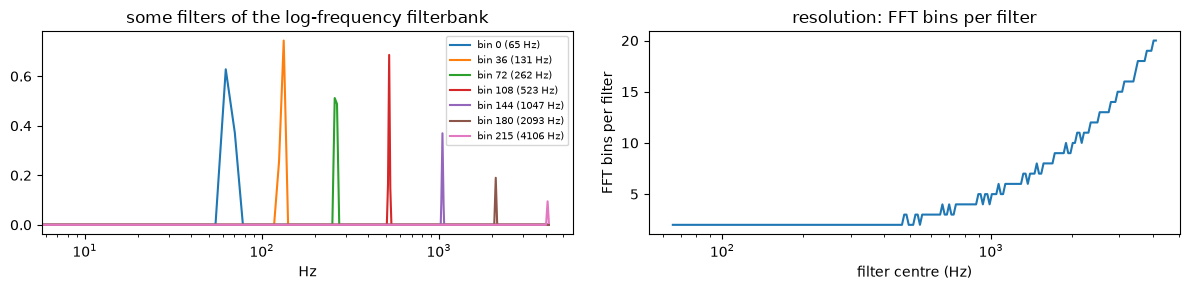

In [2]:
print(inspect.getsource(log_filterbank))
print(inspect.getsource(power_spectrogram))
print("filterbank {0} x {1}, FFT bins used: {2} of {3} (up to {4:.0f} Hz)".format(
    *FB.shape, N_FFT_USED, N_FFT // 2 + 1, N_FFT_USED * SR / N_FFT))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for k in (0, 36, 72, 108, 144, 180, 215):
    ax[0].plot(np.arange(N_FFT_USED) * SR / N_FFT, FB[k, :N_FFT_USED], label="bin {0} ({1:.0f} Hz)".format(k, CENTRES[k]))
ax[0].set_xscale("log"); ax[0].set_xlabel("Hz"); ax[0].set_title("some filters of the log-frequency filterbank"); ax[0].legend(fontsize=7)
ax[1].plot(CENTRES, (FB[:, :N_FFT_USED] > 0).sum(axis=1)); ax[1].set_xscale("log"); ax[1].set_xlabel("filter centre (Hz)")
ax[1].set_ylabel("FFT bins per filter"); ax[1].set_title("resolution: FFT bins per filter")
plt.tight_layout(); plt.show()

In [3]:
print(inspect.getsource(FrontEnd))
print(inspect.getsource(HarmonicStack))
print("harmonic shifts (bins):", dict(zip(HARMONICS, HarmonicStack().shifts)))
fe = FrontEnd().eval()
wave = torch.randn(1, 3 * SR) * 0.1
with torch.no_grad():
    a = fe.from_wave(wave)
    b = fe(torch.from_numpy(power_spectrogram(wave[0].numpy()))[None])
print("power_spectrogram (scipy) vs torch.stft inside: max |diff| of the standardised spectrogram {0:.2e}, frames {1}".format(
    (a - b).abs().max().item(), b.shape[1]))

class FrontEnd(nn.Module):
    """ power spectrum [B, T, N_FFT_USED] -> standardised log-frequency spectrogram [B, T, N_BINS];
        from_wave: waveform [B, N] (-1 .. 1) -> the same, with the STFT inside (T = N // HOP + 1) """

    def __init__(self):
        super().__init__()
        self.register_buffer("window", torch.hann_window(N_FFT))
        self.register_buffer("fb", torch.from_numpy(FB[:, :N_FFT_USED].T.copy()))   # [N_FFT_USED, N_BINS]

    def forward(self, power):
        db = 10.0 * torch.log10(torch.matmul(power, self.fb) + 1e-10)
        mean = db.mean(dim=-1, keepdim=True)
        std = torch.sqrt(((db - mean) ** 2).mean(dim=-1, keepdim=True))
        return (db - mean) / (std + 1.0)                             # silent frames stay near 0

    def from_wave(self, audio):
        # return_complex=False (real/imaginary as the last axis) is what the ONNX exporter understands
        spec = torch.stft(audio, N_FFT, HOP, N_FFT, self.window, center=True, pad_mode="reflect"

## 4. The model

Shapes: `[batch, channels, time, frequency]`. The stem reads the 1/3-semitone input (216 bins) with a 3x5 kernel
and stride 3 in frequency, so it writes one value per semitone (72); the residual blocks are depthwise-separable
(a 3x3 depthwise convolution per channel, then a 1x1 convolution across channels); the head gives one salience per
semitone which is folded to the 12 classes. BatchNorm folds into the convolutions at export.

In [4]:
print(inspect.getsource(DSBlock))
print(inspect.getsource(PitchNet2026))
model = PitchNet2026().eval()
n_params = sum(p.numel() for p in model.parameters())
print("parameters: {0:,} (old pitchnet: 22,830)".format(n_params))
from torch.utils.flop_counter import FlopCounterMode
power10 = torch.from_numpy(power_spectrogram(np.random.randn(10 * SR).astype(np.float32) * 0.1))[None]
with FlopCounterMode(display=False) as fc:
    with torch.no_grad():
        model(power10)
macs = fc.get_total_flops() / 2 / power10.shape[1]
print("multiply-adds per 10 ms frame (without the FFT): {0:.2f} M -> {1:.0f} G per 4.5 min song".format(macs / 1e6, macs * 27000 / 1e9))

class DSBlock(nn.Module):
    """ depthwise-separable residual block over (time, frequency); dil_f: frequency dilation in semitones,
        dil_t: time dilation in frames """

    def __init__(self, ch, dil_f=1, dil_t=1):
        super().__init__()
        self.dw = nn.Conv2d(ch, ch, (3, 3), padding=(dil_t, dil_f), dilation=(dil_t, dil_f), groups=ch, bias=False)
        self.pw = nn.Conv2d(ch, ch, 1, bias=False)
        self.bn = nn.BatchNorm2d(ch)
        self.act = nn.LeakyReLU(0.1)

    def forward(self, x):
        return x + self.act(self.bn(self.pw(self.dw(x))))

class PitchNet2026(nn.Module):
    """ power spectrum [B, T, N_FFT_USED] (or waveform [B, N] via forward_wave)
        -> (log probabilities of the 12 pitch classes [B, T, 12], voicing logit [B, T]) """

    def __init__(self, stem_ch=STEM_CH, ch=CH, dilations=DILATIONS, time_dilations=None):
        super().__init__()
        time_dilations = tuple(time_dilations) if time_dilations else (1,) * len(dilations)
        as

multiply-adds per 10 ms frame (without the FFT): 0.54 M -> 15 G per 4.5 min song


### Equivariance check

Two things are checked with the random weights (the values mean nothing, only the rotation):

1. **The network.** The log-frequency spectrogram of a tone is shifted by `k` semitones (3k bins) *as a tensor*
   and fed to the body; the salience per semitone (before the fold) must be the original shifted by `k`.
   The receptive field in frequency is large: the harmonic stacking reaches 28 semitones up, the dilated block
   12 more, so every position of the 72 semitone range sees the zero padding at the edges through some channel
   (a fixed context, the same in training and use, but not shift invariant). The check therefore runs on a
   spectrogram padded by 48 semitones of zeros on both sides and compares the middle 72 semitones, where the
   result has to be exact.
2. **The front end on real transpositions.** A harmonic tone is synthesised `k` semitones higher and its
   spectrogram is compared with the shifted spectrogram of the original. Here the shift is only approximate,
   because the STFT has a linear resolution: a partial is one FFT bin wide in Hz, which is a semitone at 130 Hz
   and a sixth of a semitone at 800 Hz, so the log-frequency image of a tone changes its shape when transposed
   (true for every STFT based model, RMVPE included). The table shows how much, relative to the spread of the
   spectrogram; the network has to learn this tolerance from the data (every tuning and key occurs).

In [5]:
with torch.no_grad():
    spec = model.frontend.from_wave(harmonic_tone(220.0))
    pad = 48 * BINS_PER_SEMITONE
    wide = F.pad(spec, (pad, pad))                       # 48 semitones of zeros on both sides
    sal = model.salience(wide)
    middle = slice(48, 48 + N_SEMITONES)
    print("1. network on the shifted spectrogram tensor (salience of the middle 72 semitones of the padded input):")
    print("   semitones  max|diff| / spread")
    for k in (1, 2, 5, 7, 12):
        shifted = model.salience(torch.roll(wide, shifts=k * BINS_PER_SEMITONE, dims=-1))
        rolled = torch.roll(sal, shifts=k, dims=-1)
        print("   {0:9d}  {1:16.2e}".format(k, (shifted[..., middle] - rolled[..., middle]).abs().max().item() / sal.std().item()))
    print("2. front end on a transposed tone (spectrogram vs the shifted spectrogram of the original, middle bins):")
    print("   semitones  max|diff| / spread   mean|diff| / spread   peak shift")
    cut = slice(40, N_BINS - 40)
    for k in (1, 2, 5, 7, 12):
        spec_k = model.frontend.from_wave(harmonic_tone(220.0 * 2 ** (k / 12)))
        rolled = torch.roll(spec, shifts=k * BINS_PER_SEMITONE, dims=-1)
        diff = (spec_k[..., cut] - rolled[..., cut]).abs()
        peak_shift = (spec_k[0, 100].argmax() - spec[0, 100].argmax()).item() / BINS_PER_SEMITONE
        print("   {0:9d}  {1:16.3f}   {2:17.3f}   {3:+.2f} semitones".format(
            k, diff.max().item() / spec.std().item(), diff.mean().item() / spec.std().item(), peak_shift))

1. network on the shifted spectrogram tensor (salience of the middle 72 semitones of the padded input):
   semitones  max|diff| / spread
           1          0.00e+00
           2          0.00e+00
           5          0.00e+00
           7          0.00e+00
          12          0.00e+00
2. front end on a transposed tone (spectrogram vs the shifted spectrogram of the original, middle bins):
   semitones  max|diff| / spread   mean|diff| / spread   peak shift
           1             1.742               0.063   +1.00 semitones
           2             1.649               0.143   +2.00 semitones
           5             1.658               0.179   +5.00 semitones
           7             2.493               0.215   +7.00 semitones
          12             1.424               0.304   +12.00 semitones


## 5. ONNX export of the untrained model and its runtime

Deployed model: input `power` `[batch, frames, 536]` float32 (from `power_spectrogram`), outputs `pitch_logprob`
`[batch, frames, 12]` and `voicing` `[batch, frames]`; frame `t` is centred at `t * 10 ms`. The waveform variant
(`..._wave.onnx`, input `audio` `[batch, samples]` in -1 .. 1) has the STFT inside.

The runtime is measured on `dev/testdata/song.mp3` (4.5 min, 16 kHz int16 from ffmpeg as in the tool) against the
old pitchnet path (`AudioPreprocessor` + `PitchClassifier`) on the same audio, whole song and in 20 s chunks.

In [6]:
import onnx, onnxruntime as ort
MODELS.mkdir(exist_ok=True)
onnx_path = MODELS / (MODEL_NAME + "_untrained.onnx")
onnx_wave_path = MODELS / (MODEL_NAME + "_untrained_wave.onnx")
print(onnx_path.name, export_onnx(model, onnx_path), os.path.getsize(onnx_path) // 1024, "kB")
print(onnx_wave_path.name, export_onnx(model, onnx_wave_path, wave=True), os.path.getsize(onnx_wave_path) // 1024, "kB")


def session(path, threads=0):
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])


wave = torch.randn(1, 5 * SR) * 0.1
with torch.no_grad():
    ref, ref_v = model.forward_wave(wave)
out, out_v = session(onnx_path).run(None, {"power": power_spectrogram(wave[0].numpy())[None]})
out_w, out_wv = session(onnx_wave_path).run(None, {"audio": wave.numpy()})
print("onnx (power) vs torch: max |diff| {0:.2e} / {1:.2e}; onnx (wave) vs torch: {2:.2e} / {3:.2e}; shape {4}".format(
    np.abs(out - ref.numpy()).max(), np.abs(out_v - ref_v.numpy()).max(),
    np.abs(out_w - ref.numpy()).max(), np.abs(out_wv - ref_v.numpy()).max(), out.shape))

pitchnet_2026_11_11_untrained.onnx ['Add', 'Cast', 'Concat', 'Constant', 'ConstantOfShape', 'Conv', 'Div', 'Gather', 'Identity', 'LeakyRelu', 'Log', 'LogSoftmax', 'MatMul', 'Mul', 'Pad', 'Pow', 'ReduceLogSumExp', 'ReduceMax', 'ReduceMean', 'Reshape', 'Shape', 'Slice', 'Sqrt', 'Squeeze', 'Sub', 'Transpose', 'Unsqueeze'] 492 kB
pitchnet_2026_11_11_untrained_wave.onnx ['Add', 'Cast', 'Concat', 'Constant', 'ConstantOfShape', 'Conv', 'Div', 'Gather', 'Identity', 'LeakyRelu', 'Log', 'LogSoftmax', 'MatMul', 'Mul', 'Pad', 'Pow', 'ReduceLogSumExp', 'ReduceMax', 'ReduceMean', 'ReduceSum', 'Reshape', 'STFT', 'Shape', 'Slice', 'Sqrt', 'Squeeze', 'Sub', 'Transpose', 'Unsqueeze'] 504 kB


onnx (power) vs torch: max |diff| 4.77e-07 / 2.61e-08; onnx (wave) vs torch: 4.77e-07 / 2.61e-08; shape (1, 501, 12)


In [7]:
import logging
logging.disable(logging.WARNING)
from ultrastar_pitch.project_parser import ProjectParser
from ultrastar_pitch.audio_preprocessor import AudioPreprocessor
from ultrastar_pitch.pitch_classifier import PitchClassifier

parser = ProjectParser(); parser.load_note_file(str(ROOT / "dev" / "testdata" / "notes.txt"))
t0 = time.time(); mix = parser.load_main_audio(SR); t_ffmpeg = time.time() - t0
audio = mix.astype(np.float32) / 32768.0
print("song: {0:.0f} s, {1} notes, ffmpeg decode {2:.2f} s".format(len(mix) / SR, len(parser.singable), t_ffmpeg))

# old pitchnet on the same song
t0 = time.time()
pre, clf = AudioPreprocessor(stride=128), PitchClassifier(str(ROOT / "ultrastar_pitch" / "binaries" / "pitchnet_2020_12_14.onnx"))
clf.predict(np.vstack([pre.transform(mix[s:e]) for s, e in parser.note_bounds(SR)])); t_old = time.time() - t0


def run_chunks(sess, power, chunk=2000, margin=100):
    ''' the model on chunks of frames with a margin (RMVPE style), the margins dropped '''
    parts, pos, n = [], 0, power.shape[1]
    while pos < n:
        s, e = max(0, pos - margin), min(n, pos + chunk + margin)
        lp, _ = sess.run(None, {"power": power[:, s:e]})
        parts.append(lp[:, pos - s:pos - s + min(chunk, n - pos)])
        pos += chunk
    return np.concatenate(parts, axis=1)


t0 = time.time(); power = power_spectrogram(audio)[None]; t_fft = time.time() - t0
t0 = time.time(); power_spectrogram(audio, workers=1); t_fft1 = time.time() - t0
print("power_spectrogram (scipy.fft): {0:.2f} s with all cores, {1:.2f} s with one; frames {2} (expected {3})".format(
    t_fft, t_fft1, power.shape[1], len(mix) // HOP + 1))
print("threads   power model: whole   chunks   | wave model (STFT inside): whole   | max|diff| whole vs chunks")
rows = []
for threads in (1, 0):
    sess, sess_w = session(onnx_path, threads), session(onnx_wave_path, threads)
    sess.run(None, {"power": power[:, :500]}); sess_w.run(None, {"audio": audio[None, :SR]})   # warm up
    t0 = time.time(); whole, _ = sess.run(None, {"power": power}); t_whole = time.time() - t0
    t0 = time.time(); chunked = run_chunks(sess, power); t_chunk = time.time() - t0
    t0 = time.time(); sess_w.run(None, {"audio": audio[None]}); t_wave = time.time() - t0
    fft = t_fft1 if threads == 1 else t_fft
    rows.append((threads or os.cpu_count(), fft + t_whole, fft + t_chunk, t_wave))
    print("{0:7d}   {1:17.2f} s {2:6.2f} s   | {3:27.2f} s   | {4:.2e}".format(
        rows[-1][0], rows[-1][1], rows[-1][2], t_wave, np.abs(whole - chunked).max()))
print("(power model: the FFT of power_spectrogram with the same number of threads included)")
print("old pitchnet (DCT + onnx, all threads): {0:.2f} s; ffmpeg: {1:.2f} s".format(t_old, t_ffmpeg))
budget = 2 * (t_ffmpeg + t_old) - t_ffmpeg
print("budget for the new model (tool runtime doubled): {0:.2f} s -> one thread {1}, all threads {2}".format(
    budget, "ok" if rows[0][1] <= budget else "over", "ok" if rows[-1][1] <= budget else "over"))

song: 273 s, 179 notes, ffmpeg decode 0.96 s


power_spectrogram (scipy.fft): 0.22 s with all cores, 0.28 s with one; frames 27306 (expected 27306)
threads   power model: whole   chunks   | wave model (STFT inside): whole   | max|diff| whole vs chunks


      1                2.16 s   1.61 s   |                        3.83 s   | 0.00e+00


     16                0.85 s   0.57 s   |                        2.54 s   | 4.77e-07
(power model: the FFT of power_spectrogram with the same number of threads included)
old pitchnet (DCT + onnx, all threads): 0.26 s; ffmpeg: 0.96 s
budget for the new model (tool runtime doubled): 1.48 s -> one thread over, all threads ok


## 6. Data

`dev/pitchnet_data.py plan` selects and splits the songs (no audio read), `extract` writes the cache. The
selection of the current plan:

In [8]:
plan_file = LISTS / "plan.txt"
print(plan_file.read_text(encoding="utf-8") if plan_file.exists() else "no plan yet: run dev/pitchnet_data.py plan")

12886 rows in dev/results/scores.csv, 12336 with status ok
duplicate groups: 11188 groups of 12736 songs, 1267 groups with more than one song (68 s)
evaluation songs: 200 (4 not in the csv, excluded by folder/title only); excluded from the training: 196 evaluation song, 23 same artist/title, 11 duplicate group of an evaluation song, 4 same folder
selected 5032 songs; dropped: 6306 quality_score < 0.5, 715 |drift| > 20.0 ms/min, 400 status skipped_duet, 229 evaluation song or related, 51 timing_confidence < 0.5, 3 notes beyond the audio
transposition applied to 17 songs (|shift| >= 0.5 semitones and pitch_score_aligned - pitch_score >= 0.1)
offset correction: |offset| > 50 ms in 1295 songs, > 100 ms in 98, max 180 ms
train: 4783 songs, 1886271 notes
val: 249 songs, 100914 notes
test: 200 evaluation songs (dev/lists/rmvpe_batch_songs*.txt), not used for any decision
cache size for mix + vocals as int16: about 76 GB



### The cache format, the dataset and the augmentations

Per song `<id>.mix.npy` and `<id>.vocals.npy` (int16, 16 kHz, same length, memory mapped) and `<id>.labels.npz`:
`labels` (int8 per 10 ms frame, -1 .. 11), `voicing` (int8, -1 ignore / 0 / 1), `segments` and `classes` of the
notes (offset and transposition corrected) for the note-level validation. `pitchnet_data.py show <id>` checks the
alignment of one song: the vocals must be loudest inside the labeled frames, not 50 or 100 ms before or after.

A training example is a random crop of 4 s (`SongCrops` in `pitchnet_train.py`, its docstring lists the
augmentations). The STFT of the crops runs in torch on the GPU (`forward_wave`).


@file          pitchnet_train.py
@brief         train pitchnet_2026 on the cache of pitchnet_data.py (one run = one folder of results)
@author        paradigm

    python dev/pitchnet_train.py --name base --loss smooth --aug remix,gain,polarity
    python dev/pitchnet_train.py --name near --loss neighbour --aug remix,gain,polarity,tuning,noise

Writes dev/results/pitchnet_runs/<name>/: log.txt, history.json (one entry per epoch), best.pt (the epoch with
the best exact note accuracy on the validation songs with the mix as input), model.onnx and model_wave.onnx of it.

Training examples are random crops of CROP_S seconds of the cached songs (dev/pitchnet_2026.ipynb explains the
cache). Augmentations (--aug):
  remix      the accompaniment (mix - vocals) is added to the vocals with a random gain: half of the crops the
             original mix (gain 1), a quarter the vocals alone (gain 0), the rest a gain in 0 .. 1.5. Without
             it every crop is the mix
  gain       random leve

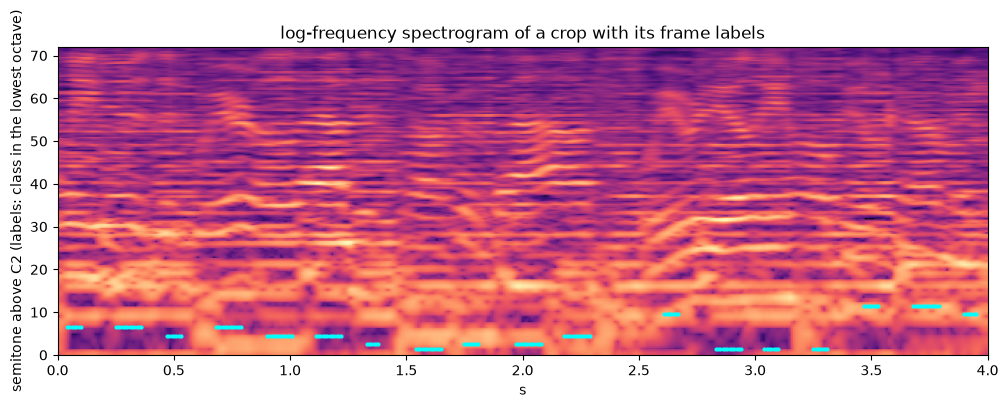

In [9]:
import pitchnet_train as pt
print(pt.__doc__)
print(inspect.getsource(pt.SongCrops))
val_rows, train_rows = pt.read_selection("val"), pt.read_selection("train")
print("cached songs: train {0}, val {1}".format(len(train_rows), len(val_rows)))
if val_rows:
    ds = pt.SongCrops(val_rows[:2], crops_per_song=2, aug=("remix", "gain", "polarity"))
    x, y, w = ds[0]
    print("crop:", x.shape, "labels", y.shape, "labeled frames", int((y >= 0).sum()), "voiced", int((w == 1).sum()), "unvoiced", int((w == 0).sum()))
    with torch.no_grad():
        spec = model.frontend.from_wave(x[None])[0].numpy()
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.imshow(spec.T, origin="lower", aspect="auto", extent=(0, pt.CROP_S, 0, N_SEMITONES), cmap="magma")
    t = np.arange(len(y)) * HOP / SR
    for cls in range(12):
        sel = y.numpy() == cls
        if sel.any():
            ax.scatter(t[sel], np.full(sel.sum(), cls + 0.5), s=4, c="cyan")   # the class, drawn in the lowest octave
    ax.set_xlabel("s"); ax.set_ylabel("semitone above C2 (labels: class in the lowest octave)")
    ax.set_title("log-frequency spectrogram of a crop with its frame labels"); plt.show()

## 7. Training

`pitchnet_train.py` trains one configuration per call (AdamW, one-cycle schedule, 30 epochs of 8 crops per song)
and selects the epoch on the **note-level** exact accuracy of the validation songs with the mix as input (the
pipeline's metric: probabilities summed inside every note, argmax, compared with the corrected label); the vocals
input and the within-one-semitone accuracy are reported as well. The runs compared here:

| run | loss | augmentation |
|---|---|---|
| `base` | label smoothing 0.05 | remix, gain, polarity |
| `near` | neighbour target (one semitone off is a small error) | remix, gain, polarity |
| `near_aug` | neighbour target | remix, gain, polarity, tuning (+-0.35 semitones), noise |

    python dev/pitchnet_train.py --name base     --loss smooth    --aug remix,gain,polarity
    python dev/pitchnet_train.py --name near     --loss neighbour --aug remix,gain,polarity
    python dev/pitchnet_train.py --name near_aug --loss neighbour --aug remix,gain,polarity,tuning,noise

The losses:

In [10]:
print(inspect.getsource(pt.pitch_loss))
print(inspect.getsource(pt.note_accuracy))

def pitch_loss(logprob, y, kind: str) -> torch.Tensor:
    """ logprob [N, 12], y [N] with -1 = ignore """
    valid = y >= 0
    if not valid.any():
        return logprob.sum() * 0.0
    logprob, y = logprob[valid], y[valid]
    if kind == "smooth":
        return F.cross_entropy(logprob, y, label_smoothing=0.05)
    if kind == "neighbour":
        eps, delta = 0.05, 0.05
        target = torch.full_like(logprob, eps / 12)
        idx = torch.arange(len(y), device=y.device)
        target[idx, y] += 1.0 - eps - 2 * delta
        target[idx, (y + 1) % 12] += delta
        target[idx, (y - 1) % 12] += delta
        return -(target * logprob).sum(dim=1).mean()
    raise ValueError("unknown loss " + kind)

def note_accuracy(net, rows, device, source="mix", chunk_s=30) -> dict:
    """ exact and within-one-semitone pitch class accuracy per note (probabilities summed inside the note) """
    net.eval()
    hit = near = total = 0
    with torch.no_grad():
        for r in rows:
            

run        epochs    mix exact  mix within1   vocals exact vocals within1   loss / augmentation
base        29/30       84.20%       89.64%         83.09%         92.37%   smooth / remix,gain,polarity
ch64        27/30       84.67%       90.04%         83.38%         92.53%   smooth / remix,gain,polarity
near        30/30       84.13%       89.65%         83.08%         92.51%   neighbour / remix,gain,polarity
near_aug    23/30       83.80%       89.40%         83.07%         92.46%   neighbour / remix,gain,polarity,tuning,noise
tdil4b      26/30       84.29%       89.32%         83.29%         91.47%   smooth / remix,gain,polarity


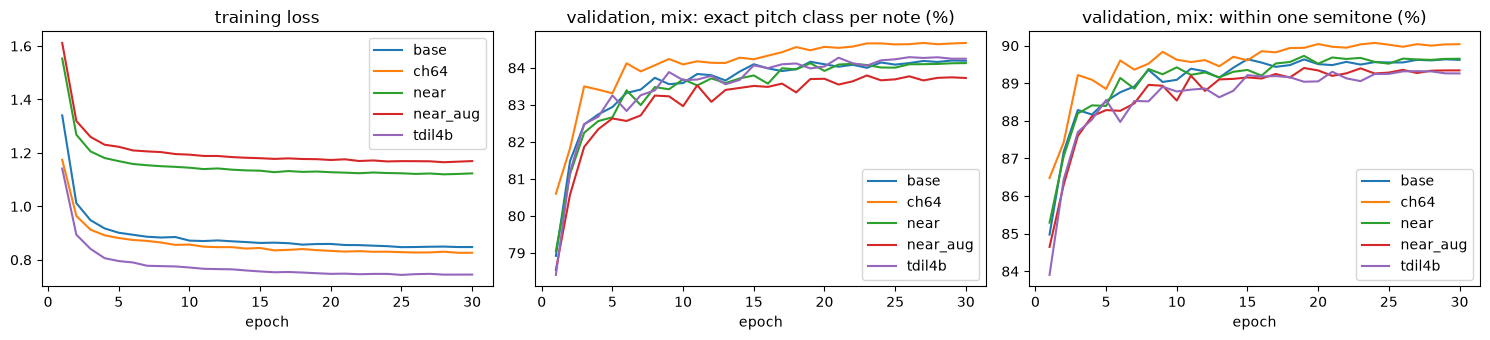

In [11]:
runs = {}
for path in sorted(RUNS.glob("*/history.json")):
    if path.parent.name == "smoke":
        continue
    with open(path, encoding="utf-8") as file:
        runs[path.parent.name] = json.load(file)
if not runs:
    print("no training runs yet (dev/results/pitchnet_runs/)")
else:
    print("{0:10s} {1:>6s} {2:>12s} {3:>12s} {4:>14s} {5:>14s}   {6}".format(
        "run", "epochs", "mix exact", "mix within1", "vocals exact", "vocals within1", "loss / augmentation"))
    for name, run in runs.items():
        h = run["history"]
        best = max(h, key=lambda e: e["mix_exact"])
        print("{0:10s} {1:3d}/{2:<3d} {3:11.2%} {4:12.2%} {5:14.2%} {6:14.2%}   {7} / {8}".format(
            name, best["epoch"], len(h), best["mix_exact"], best["mix_within1"], best["vocals_exact"], best["vocals_within1"],
            run["args"]["loss"], run["args"]["aug"]))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    for name, run in runs.items():
        h = run["history"]
        ax[0].plot([e["epoch"] for e in h], [e["loss"] for e in h], label=name)
        ax[1].plot([e["epoch"] for e in h], [100 * e["mix_exact"] for e in h], label=name)
        ax[2].plot([e["epoch"] for e in h], [100 * e["mix_within1"] for e in h], label=name)
    ax[0].set_title("training loss"); ax[1].set_title("validation, mix: exact pitch class per note (%)")
    ax[2].set_title("validation, mix: within one semitone (%)")
    for a in ax:
        a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()

### Choosing between the runs

The three runs of the first round (`base`, `near`, `near_aug`; `ch64` and `tdil4b` in the table above belong to
the second round, section 9) end within 0.4 points of each other, too close for the pooled numbers alone. Two measurements on
the validation songs decide (the test songs are not used for any choice):

1. `dev/pitchnet_val_compare.py` runs the exported `model.onnx` of every run through the package code
   (`power_spectrogram`, `PitchClassifier.predict_power`, `frame_scores_per_note`) on the mix, the vocals and the
   mix resampled by +-0.29 semitones (a detuned song; 432 Hz tuning is -0.32 semitones), paired per song with a
   bootstrap over the songs. It also checks the export: the package path reproduces the training numbers.
2. `dev/tuning_survey.py` measures how often songs are detuned at all: the RMVPE tuning estimate of the pipeline
   (circular mean of the voice f0 inside the notes) on 600 random songs of the database, without the label
   quality filter of the training selection and without the evaluation songs.

In [12]:
for name in ("pitchnet_runs/val_compare.txt", "tuning_survey.txt"):
    path = ROOT / "dev" / "results" / name
    print("=== dev/results/" + name)
    print(path.read_text(encoding="utf-8") if path.exists() else "not measured yet")

=== dev/results/pitchnet_runs/val_compare.txt
249 validation songs, 100914 notes; models: base, near, near_aug

mix
  run          exact  within 1  1 st of errs   exact - base [95 % over songs]
  base        84.21%    89.65%         34.4%
  near        84.14%    89.66%         34.8%   -0.07 [-0.19 .. +0.04] points
  near_aug    83.81%    89.41%         34.6%   -0.40 [-0.58 .. -0.21] points

vocals
  run          exact  within 1  1 st of errs   exact - base [95 % over songs]
  base        83.09%    92.38%         54.9%
  near        83.08%    92.51%         55.7%   -0.01 [-0.10 .. +0.08] points
  near_aug    83.07%    92.46%         55.5%   -0.02 [-0.15 .. +0.11] points

mix +0.29 st
  run          exact  within 1  1 st of errs   exact - base [95 % over songs]
  base        79.09%    87.87%         42.0%
  near        78.98%    88.03%         43.0%   -0.12 [-0.27 .. +0.02] points
  near_aug    80.86%    89.10%         43.1%   +1.77 [+1.45 .. +2.08] points

mix -0.29 st
  run          ex

Result: the neighbour loss (`near`) changes nothing measurable, not even the share of the errors that are one
semitone off. The tuning augmentation (`near_aug`) costs 0.4 points on the songs as they are and gains 2 to 5
points on songs detuned by 0.29 semitones; without it the model loses 5 to 9 points there. But only 2.7 % of the
songs are 25 cents or more off (9.8 % at 15 cents, median 2.7 cents), so the augmentation would gain about 0.1
points on average and lose 0.2 to 0.4 on all the other songs. In the full pipeline (ensemble with RMVPE, vocals,
pooling, key prior; next section) `near_aug` is 0.2 to 0.3 points behind on the mix and equal with the vocals.
Chosen: `base`, the simplest of the three.

### The chosen model

`CHOSEN_RUN` names the run that became the first version `models/pitchnet_2026_11_11.onnx` (+ `_wave.onnx`,
`.pt`), packaged until the second round (section 9) replaced it.

In [13]:
CHOSEN_RUN = "base"
if CHOSEN_RUN and (RUNS / CHOSEN_RUN / "best.pt").exists():
    import shutil
    net, ckpt = pm.load_checkpoint(RUNS / CHOSEN_RUN / "best.pt")
    shutil.copy(RUNS / CHOSEN_RUN / "best.pt", MODELS / (MODEL_NAME + ".pt"))
    print(MODEL_NAME + ".onnx", export_onnx(net, MODELS / (MODEL_NAME + ".onnx")))
    export_onnx(net, MODELS / (MODEL_NAME + "_wave.onnx"), wave=True)
    print("epoch {0}: {1}".format(ckpt["epoch"], ckpt["val"]))
else:
    print("no run chosen yet")

pitchnet_2026_11_11.onnx ['Add', 'Cast', 'Concat', 'Constant', 'ConstantOfShape', 'Conv', 'Div', 'Gather', 'LeakyRelu', 'Log', 'LogSoftmax', 'MatMul', 'Mul', 'Pad', 'Pow', 'ReduceLogSumExp', 'ReduceMax', 'ReduceMean', 'Reshape', 'Shape', 'Slice', 'Sqrt', 'Squeeze', 'Sub', 'Transpose', 'Unsqueeze']


epoch 29: {'epoch': 29, 'loss': 0.8478499460260273, 'mix_exact': 0.8419941732564362, 'mix_within1': 0.8963771131854846, 'vocals_exact': 0.8308857046594129, 'vocals_within1': 0.9237073151396238, 'train_s': 86.31749892234802, 'epoch_s': 110.80805730819702}


## 8. Evaluation

1. **Integration.** `PitchClassifier` recognises the new model by its input name `power`: the ONNX is run once on
   the whole mix (and once on the vocals when present, in 20 s chunks with a margin) after `power_spectrogram`,
   the probabilities are summed per note exactly as `rmvpe.chroma_per_note` does. The old model stays loadable
   for the comparison (`--pitchnet-model`).
2. **Ensemble weights, on the validation songs.** `DetectionPipeline` combines per note
   `w * RMVPE + (1 - w) * pitchnet` (log domain), the vocals with `(1 - v) * mix + v * vocals`, then repetition
   pooling and the soft key prior with weight `k`. The weights `w = 0.6, v = 0.35, k = 0.25` were set with the old
   pitchnet. `dev/pipeline_weights_val.py` caches the per note scores of RMVPE, the old pitchnet and the three runs
   on the mix and the vocals of the 249 validation songs (the steps of `DetectionPipeline.transform`, with the timing
   correction) and combines them for a grid of weights exactly like the pipeline, scored like `pipeline_eval.py`.

In [14]:
for name in ("pipeline_weights_val.txt", "pipeline_weights_val_fine.txt"):
    path = ROOT / "dev" / "results" / name
    print("=== dev/results/" + name)
    print(path.read_text(encoding="utf-8") if path.exists() else "not measured yet")

=== dev/results/pipeline_weights_val.txt
249 validation songs with mix and vocals (249 cached), 100914 notes; models: old, base, near, near_aug
grid of 448 settings in 1109 s
current weights: RMVPE w 0.6, vocals v 0.35, key prior k 0.25

=== mix (ensemble+pp): exact %, rows RMVPE weight w, columns key prior k
  old                k=0.0     k=0.15    k=0.25    k=0.4  
    w=0.0             78.99     80.18     80.34     80.31 
    w=0.2             80.45     81.75     81.90     81.82 
    w=0.3             80.96     82.39     82.47     82.37 
    w=0.4             81.33     82.90     82.98     82.81 
    w=0.5             81.55     83.19     83.25     83.05 
    w=0.6             81.53     83.34     83.31     83.15 
    w=0.8             80.87     82.96     82.74     82.40 
  base               k=0.0     k=0.15    k=0.25    k=0.4  
    w=0.0             84.53     85.07     84.85     84.40 
    w=0.2             85.06     85.78     85.53     85.11 
    w=0.3             85.08     85.91   

The old pitchnet is at its optimum with its weights (+0.03 points at most), which confirms the earlier tuning
and the validation songs as a reference. The new model wants much less RMVPE (`w` 0.25 instead of 0.6), more
vocals (`v` 0.5 instead of 0.35) and a weaker key prior (`k` 0.15 instead of 0.25); the optimum is flat around
these values. With its own weights the new model gains +2.6 points over the old pipeline on the mix and +2.1 with
the vocals (validation songs, 85.9 % and 87.5 % exact). `DetectionPipeline` uses these weights whenever the pitch
classifier is a frame model and the old ones for the old model.

3. **Same test, same metric.** `dev/pipeline_eval.py` on the 197 evaluation songs (`dev/lists/rmvpe_batch_songs*.txt`,
   never seen in training or in any choice, duplicates removed) in the configurations of the old logs, paired per
   song against the old model with `dev/pipeline_compare.py`.

In [15]:
import subprocess
new_log = ROOT / "dev" / "results" / "pipeline_eval_2026.log"
old_now = ROOT / "dev" / "results" / "pipeline_eval_2020_now.log"
if not new_log.exists():
    print("test evaluation not run yet")
else:
    for log in (new_log, old_now):
        if log.exists():
            text = log.read_text(encoding="utf-8").splitlines()
            start = next((i for i, line in enumerate(text) if " songs in " in line), None)
            print("=== " + log.name)
            print("\n".join(text[:1] + (text[start:] if start is not None else ["(still running)"])))
    pairs = [("pipeline_eval.log:pitchnet", "pipeline_eval_2026.log:pitchnet"),
             ("pipeline_eval.log:ensemble", "pipeline_eval_2026.log:ensemble@file"),
             ("pipeline_eval_rep.log:ensemble+pp", "pipeline_eval_2026.log:ensemble+pp@file"),
             ("pipeline_eval_rep.log:vocals+pp", "pipeline_eval_2026.log:vocals+pp@file"),
             ("pipeline_eval_timing.log:ensemble+pp", "pipeline_eval_2026.log:ensemble+pp"),
             ("pipeline_eval_timing.log:vocals+pp", "pipeline_eval_2026.log:vocals+pp")]
    # reproduction check: the old model with today's code must give the old logs per song
    pairs += [("pipeline_eval_timing.log:ensemble+pp", "pipeline_eval_2020_now.log:ensemble+pp"),
              ("pipeline_eval_timing.log:vocals+pp", "pipeline_eval_2020_now.log:vocals+pp")]
    for a, b in pairs:
        res = subprocess.run([sys.executable, str(ROOT / "dev" / "pipeline_compare.py"), str(ROOT / "dev" / "results" / a),
                              str(ROOT / "dev" / "results" / b)], capture_output=True, text=True)
        print("\n" + a + "  vs  " + b + "\n" + res.stdout.strip())

=== pipeline_eval_2026.log
pitch classifier: pitchnet_2026_11_11.onnx (frame model)
200 songs in 90.5 min
configuration    songs   notes |   exact      ±1    soft | song mean  >=80% | exact by length (ms)     <60  60-100 100-200 200-400 400-800    >800
pitchnet           197   73971 |   74.8%   81.9%   83.0% |     75.1%  50.8% |                         54.2    66.1    73.3    79.9    87.7    89.1
ensemble@file      197   73971 |   75.5%   82.7%   83.7% |     75.9%  53.8% |                         55.5    67.6    74.1    80.2    88.1    90.1
ensemble+pp@file   197   73971 |   77.6%   82.8%   84.4% |     77.8%  58.9% |                         59.6    70.3    77.1    81.1    88.4    89.5
vocals+pp@file     197   73971 |   79.0%   84.5%   85.9% |     79.2%  62.4% |                         60.8    71.7    78.6    82.4    89.5    90.3
ensemble+pp        197   73971 |   81.3%   86.2%   87.3% |     81.1%  66.0% |                         63.8    75.4    80.2    85.6    89.5    91.3
vocals+pp   


pipeline_eval.log:pitchnet  vs  pipeline_eval_2026.log:pitchnet
197 songs | pitchnet: 68.87 % | pitchnet: 75.10 % | song mean
pitchnet - pitchnet: +6.23 points [+5.43 .. +7.11], better in 179 songs, worse in 15



pipeline_eval.log:ensemble  vs  pipeline_eval_2026.log:ensemble@file
197 songs | ensemble: 72.14 % | ensemble@file: 75.86 % | song mean
ensemble@file - ensemble: +3.72 points [+3.18 .. +4.26], better in 173 songs, worse in 22



pipeline_eval_rep.log:ensemble+pp  vs  pipeline_eval_2026.log:ensemble+pp@file
197 songs | ensemble+pp: 75.57 % | ensemble+pp@file: 77.82 % | song mean
ensemble+pp@file - ensemble+pp: +2.25 points [+1.80 .. +2.71], better in 150 songs, worse in 42



pipeline_eval_rep.log:vocals+pp  vs  pipeline_eval_2026.log:vocals+pp@file
197 songs | vocals+pp: 77.10 % | vocals+pp@file: 79.24 % | song mean
vocals+pp@file - vocals+pp: +2.14 points [+1.73 .. +2.57], better in 157 songs, worse in 31



pipeline_eval_timing.log:ensemble+pp  vs  pipeline_eval_2026.log:ensemble+pp
197 songs | ensemble+pp: 78.72 % | ensemble+pp: 81.14 % | song mean
ensemble+pp - ensemble+pp: +2.42 points [+1.95 .. +2.91], better in 150 songs, worse in 39



pipeline_eval_timing.log:vocals+pp  vs  pipeline_eval_2026.log:vocals+pp
197 songs | vocals+pp: 80.32 % | vocals+pp: 82.41 % | song mean
vocals+pp - vocals+pp: +2.10 points [+1.71 .. +2.51], better in 162 songs, worse in 28



pipeline_eval_timing.log:ensemble+pp  vs  pipeline_eval_2020_now.log:ensemble+pp
197 songs | ensemble+pp: 78.72 % | ensemble+pp: 78.72 % | song mean
ensemble+pp - ensemble+pp: +0.00 points [+0.00 .. +0.00], better in 0 songs, worse in 0



pipeline_eval_timing.log:vocals+pp  vs  pipeline_eval_2020_now.log:vocals+pp
197 songs | vocals+pp: 80.32 % | vocals+pp: 80.32 % | song mean
vocals+pp - vocals+pp: +0.00 points [+0.00 .. +0.00], better in 0 songs, worse in 0


**Result on the test songs** (197 songs, 73,971 notes, measured 2026-11-13). The old model run again with today's
code gives the old logs song by song (0 songs different), so the differences come from the model and its weights.
The new model is better in every configuration, by about as much as on the validation songs:

| configuration | old model | new model | paired difference (song mean, 95 % bootstrap) |
|---|---|---|---|
| pitch model alone | 68.4 % | 74.8 % | +6.2 [+5.4 .. +7.1] |
| ensemble, file timing | 71.6 % | 75.5 % | +3.7 [+3.2 .. +4.3] |
| ensemble+pp, file timing | 75.3 % | 77.6 % | +2.3 [+1.8 .. +2.7] |
| vocals+pp, file timing | 76.8 % | 79.0 % | +2.1 [+1.7 .. +2.6] |
| ensemble+pp (the default) | 78.8 % | 81.3 % | +2.4 [+2.0 .. +2.9] |
| vocals+pp (with `--separate`) | 80.3 % | 82.5 % | +2.1 [+1.7 .. +2.5] |

The percentages are pooled over all notes, the differences are paired per song (song mean). The default
pipeline is better in 150 songs and worse in 39, with the vocals better in 162 and worse in 28. By note length (pooled, no
interval) the gain is about +2 to +3 points for the notes up to 400 ms and +1.5 to +1.8 for the longer ones. Notes more than one semitone off (the gross errors for the game) drop
from 15.4 % to 13.8 % in the default pipeline and from 13.4 % to 12.2 % with the vocals.

## 9. Second round: width, time context, tuning correction, note context network

The first version showed no gap between training and validation songs (mix 83.8 vs 84.2 % exact): it was limited
by its capacity (or by the labels), not by the amount of data. Four follow-ups, all chosen on the 249 validation
songs, the test songs used once at the end:

1. **Width.** `ch64` (`--ch 64`, 64 instead of 32 channels, 17,155 parameters) reaches 84.67 % on the validation
   mix (`base` 84.20 %). Runtime on the 273 s song of section 5: 1.20 s instead of 0.75 s with all threads, within
   the budget of 1.50 s.
2. **Time context.** `tdil4b` (`--dilations 1,12,1,12 --time-dilations 1,2,4,8`, +-31 frames instead of +-4)
   reaches 84.29 %; in the pipeline +0.16 points, not significant. Dropped.
3. **Tuning correction instead of augmentation.** The RMVPE tuning estimate of the voice, which the pipeline
   computes anyway, shifts the power spectrum before the model (`pitch_classifier.shift_power`,
   `DetectionPipeline.FRAME_TUNING_CENTS`). On songs in tune it changes nothing; songs detuned by +-29 cents go
   back from 79 % / 75 % to 84 % (`dev/pitchnet_tuning_val.py`). In the pipeline it adds little to `base`
   (+0.12, not significant) but more to `ch64`; all thresholds from 0 to 20 cents are equal, so it is always on
   when the estimate is reliable.
4. **Note context network.** A bidirectional GRU over the notes of a song corrects the decision of the
   postprocessing from the neighbouring notes (`dev/context_gru_2026.py`, in the tool `ultrastar_pitch/context_model.py`).
   Trained on the pipeline scores of the 4781 training songs it gains +2.2 points on the validation mix (with 529
   songs only +1.2). A transformer of the same size reached half of that; the syllables of the lyrics added nothing.

The pipeline configurations on the validation songs (cached scores, exactly the steps of `DetectionPipeline`),
the tuning thresholds with `ch64`, the training of the chosen network and the test of the final configuration on
the cached scores of the 197 evaluation songs (they reproduce the real pipeline song by song):

In [16]:
for name in ("pipeline_compare_val_2026b.txt", "pipeline_tuning_policy_val_ch64.txt", "gru2026_ch64t_gru96.txt",
             "final_config_test_2026b.txt"):
    path = ROOT / "dev" / "results" / name
    print("=== dev/results/" + name)
    print(path.read_text(encoding="utf-8") if path.exists() else "not measured yet")

=== dev/results/pipeline_compare_val_2026b.txt
mix (w 0.25, v 0.5, k 0.15): 249 songs (0 without all scores skipped), 100914 notes
  base           exact  85.88 %  within 1  89.71 %   vs base +0.00 [+0.00 .. +0.00], songs better 0, worse 0
  ch64           exact  86.16 %  within 1  89.98 %   vs base +0.28 [+0.02 .. +0.46], songs better 151, worse 54
  tdil4b         exact  86.04 %  within 1  89.85 %   vs base +0.16 [-0.19 .. +0.47], songs better 135, worse 95
  base@10        exact  86.03 %  within 1  89.79 %   vs base +0.16 [-0.04 .. +0.40], songs better 15, worse 5
  ch64@10        exact  86.43 %  within 1  90.09 %   vs base +0.55 [+0.34 .. +0.83], songs better 155, worse 52
  ch64@0         exact  86.43 %  within 1  90.07 %   vs base +0.55 [+0.34 .. +0.82], songs better 159, worse 58
mix + vocals (w 0.25, v 0.5, k 0.15): 249 songs (0 without all scores skipped), 100914 notes
  base           exact  87.49 %  within 1  91.50 %   vs base +0.00 [+0.00 .. +0.00], songs better 0, worse 0


### The packaged model

`CHOSEN_RUN_2` names the run that becomes `models/pitchnet_2026_11_13.onnx` (+ `_wave.onnx`, `.pt`), the packaged
`ultrastar_pitch/binaries/pitchnet_2026_11_13.onnx`; the cell checks that the export is the packaged file.

In [17]:
CHOSEN_RUN_2, NAME_2 = "ch64", "pitchnet_2026_11_13"
if (RUNS / CHOSEN_RUN_2 / "best.pt").exists():
    import hashlib
    import shutil
    net2, ckpt2 = pm.load_checkpoint(RUNS / CHOSEN_RUN_2 / "best.pt")
    shutil.copy(RUNS / CHOSEN_RUN_2 / "best.pt", MODELS / (NAME_2 + ".pt"))
    print(NAME_2 + ".onnx", export_onnx(net2, MODELS / (NAME_2 + ".onnx")))
    export_onnx(net2, MODELS / (NAME_2 + "_wave.onnx"), wave=True)
    print("epoch {0}: {1}".format(ckpt2["epoch"], ckpt2["val"]))
    md5 = lambda path: hashlib.md5(path.read_bytes()).hexdigest()   # noqa: E731
    packaged = ROOT / "ultrastar_pitch" / "binaries" / (NAME_2 + ".onnx")
    print("export identical to the packaged model:", packaged.exists() and md5(MODELS / (NAME_2 + ".onnx")) == md5(packaged))
else:
    print("run not found")

pitchnet_2026_11_13.onnx ['Add', 'Cast', 'Concat', 'Constant', 'ConstantOfShape', 'Conv', 'Div', 'Gather', 'LeakyRelu', 'Log', 'LogSoftmax', 'MatMul', 'Mul', 'Pad', 'Pow', 'ReduceLogSumExp', 'ReduceMax', 'ReduceMean', 'Reshape', 'Shape', 'Slice', 'Sqrt', 'Squeeze', 'Sub', 'Transpose', 'Unsqueeze']


epoch 27: {'epoch': 27, 'loss': 0.8278180987791001, 'mix_exact': 0.8467407891868324, 'mix_within1': 0.9004102503121469, 'vocals_exact': 0.8338089858691559, 'vocals_within1': 0.9253027330201954, 'train_s': 341.3474991321564, 'epoch_s': 445.7778196334839}
export identical to the packaged model: True


### Test of the real pipeline

`dev/pipeline_eval.py` on the 197 evaluation songs with the packaged defaults: `+pool` is the postprocessing of the
first version (repetition pooling and soft key prior), `+pp` adds the note context network; both with the new model
and the tuning correction. Paired against the first version (`pipeline_eval_2026.log`) with `dev/pipeline_compare.py`.

In [18]:
import subprocess
new_log = ROOT / "dev" / "results" / "pipeline_eval_2026_11_13.log"
if not new_log.exists():
    print("test evaluation not run yet")
else:
    text = new_log.read_text(encoding="utf-8").splitlines()
    start = next((i for i, line in enumerate(text) if " songs in " in line), None)
    print("=== " + new_log.name)
    print("\n".join(text[:1] + (text[start:] if start is not None else ["(still running)"])))
    for a, b in (("pipeline_eval_2026.log:pitchnet", "pipeline_eval_2026_11_13.log:pitchnet"),
                 ("pipeline_eval_2026.log:ensemble+pp", "pipeline_eval_2026_11_13.log:ensemble+pool"),
                 ("pipeline_eval_2026.log:ensemble+pp", "pipeline_eval_2026_11_13.log:ensemble+pp"),
                 ("pipeline_eval_2026.log:vocals+pp", "pipeline_eval_2026_11_13.log:vocals+pool"),
                 ("pipeline_eval_2026.log:vocals+pp", "pipeline_eval_2026_11_13.log:vocals+pp")):
        res = subprocess.run([sys.executable, str(ROOT / "dev" / "pipeline_compare.py"), str(ROOT / "dev" / "results" / a),
                              str(ROOT / "dev" / "results" / b)], capture_output=True, text=True)
        print("\n" + a + "  vs  " + b + "\n" + res.stdout.strip())

=== pipeline_eval_2026_11_13.log
pitch classifier: pitchnet_2026_11_13.onnx (frame model)
200 songs in 64.9 min
configuration    songs   notes |   exact      ±1    soft | song mean  >=80% | exact by length (ms)     <60  60-100 100-200 200-400 400-800    >800
pitchnet           197   73971 |   75.4%   82.3%   83.4% |     75.8%  52.8% |                         54.5    66.2    74.1    80.4    88.6    89.7
ensemble+pool      197   73971 |   81.7%   86.4%   87.5% |     81.6%  66.0% |                         63.6    75.7    80.8    85.9    90.3    91.3
vocals+pool        197   73971 |   82.9%   87.8%   88.7% |     82.7%  70.6% |                         64.9    77.2    81.8    87.1    91.3    92.0
ensemble+pp        197   73971 |   83.4%   87.5%   88.6% |     83.3%  70.6% |                         66.6    78.2    82.3    87.5    91.8    92.4
vocals+pp          197   73971 |   84.2%   88.6%   89.4% |     84.0%  72.1% |                         67.2    79.1    83.1    88.1    92.3    92.9
  ense


pipeline_eval_2026.log:pitchnet  vs  pipeline_eval_2026_11_13.log:pitchnet
197 songs | pitchnet: 75.10 % | pitchnet: 75.78 % | song mean
pitchnet - pitchnet: +0.68 points [+0.50 .. +0.86], better in 129 songs, worse in 48



pipeline_eval_2026.log:ensemble+pp  vs  pipeline_eval_2026_11_13.log:ensemble+pool
197 songs | ensemble+pp: 81.14 % | ensemble+pool: 81.57 % | song mean
ensemble+pool - ensemble+pp: +0.43 points [+0.20 .. +0.67], better in 111 songs, worse in 61



pipeline_eval_2026.log:ensemble+pp  vs  pipeline_eval_2026_11_13.log:ensemble+pp
197 songs | ensemble+pp: 81.14 % | ensemble+pp: 83.29 % | song mean
ensemble+pp - ensemble+pp: +2.15 points [+1.79 .. +2.51], better in 160 songs, worse in 31



pipeline_eval_2026.log:vocals+pp  vs  pipeline_eval_2026_11_13.log:vocals+pool
197 songs | vocals+pp: 82.41 % | vocals+pool: 82.72 % | song mean
vocals+pool - vocals+pp: +0.30 points [+0.09 .. +0.52], better in 91 songs, worse in 65



pipeline_eval_2026.log:vocals+pp  vs  pipeline_eval_2026_11_13.log:vocals+pp
197 songs | vocals+pp: 82.41 % | vocals+pp: 83.98 % | song mean
vocals+pp - vocals+pp: +1.56 points [+1.18 .. +1.95], better in 144 songs, worse in 41


**Result on the test songs** (197 songs, 73,971 notes, measured 2026-11-13 with the packaged defaults; the cached
evaluation of `dev/context_gru_2026.py` gave the same numbers to the first decimal):

| configuration | first version (2026_11_11) | packaged (2026_11_13) | paired difference (song mean, 95 % bootstrap) |
|---|---|---|---|
| pitch model alone | 74.8 % | 75.4 % | +0.68 [+0.50 .. +0.86] |
| ensemble, pooling + key prior | 81.3 % | 81.7 % | +0.43 [+0.20 .. +0.67] |
| vocals, pooling + key prior | 82.5 % | 82.9 % | +0.30 [+0.09 .. +0.52] |
| ensemble+pp with the context network (the default) | 81.3 % | 83.4 % | +2.15 [+1.79 .. +2.51] |
| vocals+pp with the context network | 82.5 % | 84.2 % | +1.56 [+1.18 .. +1.95] |

The first column is the default of the first version (pooling and key prior, no tuning correction). The context
network alone adds +1.72 [+1.41 .. +2.04] points on the mix and +1.26 [+0.95 .. +1.57] with the vocals. The default
pipeline is better in 160 songs and worse in 31. Notes more than one semitone off drop from 13.8 % to 12.5 % (with the
vocals from 12.2 % to 11.4 %); short notes gain most (below 60 ms 63.8 -> 66.6 %, 60 to 100 ms 75.4 -> 78.2 %).
Against the model of the 1.x versions the default pipeline went from 78.8 % to 83.4 % (with vocals 80.3 % -> 84.2 %).

**Update (2026-11-13, afternoon):** the packaged note context network is now the average of four such GRUs (`context_gru_ensemble_2026_11_13.onnx`: the network above, a second seed, and two networks trained on the mix and the mix + vocals scores of the training songs; mean of the log softmax, 22 ms per song). Training on the vocals scores alone changed nothing beyond the seed noise; the average gains +0.39 [+0.24 .. +0.54] points on the mix (118 songs better, 48 worse) and +0.40 [+0.22 .. +0.59] with the vocals. The default pipeline now gets 83.8 % (84.6 % with vocals), notes more than one semitone off 12.3 % (11.3 %); `dev/results/pipeline_eval_2026_11_13b.log`, `pipeline_compare_2026_11_13b.txt`, `gru2026_vocals_ensemble_{val,test}.txt`.

## 10. Open points

* The labels are karaoke files: around 15 to 25 % of the notes are wrong even in the selected songs (pitch_score
  0.5 is far from 1). Label smoothing and the frame trimming are the only countermeasures here; a second round
  that re-weights the songs by the agreement between the trained model and the labels is possible.
* The note context network gained clearly with more songs (+1.2 points with 529, +2.2 with 4781 on the validation
  mix); songs outside the training selection (lower label quality) might add more, its labels are only targets
  for the correction.
* Wider than 64 channels exceeds the CPU budget; a larger model only for the GPU would be possible.
* Synthetic data (harmonic tones with known pitch) could teach the low octave, where the STFT is coarse; not
  used, because its effect would have to be measured against the real validation songs first.
* The neighbour loss brought nothing measurable; a loss that weights the errors by the game's scoring would need a
  metric of the game first.
* Voicing: the voicing output against the RMVPE voicing on the same frames, and the timing check with each of them.